In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

In [2]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/AllInOne_2022/Res_LL_lxy.coffea"

sig_histo = util.load(f_sig) [0]

sum_counts= [[1.1084e+04 7.6790e+03 8.0000e+02 1.0700e+02 2.0000e+01]
 [3.0121e+04 3.3221e+04 7.0800e+03 1.6150e+03 4.3900e+02]
 [2.1926e+04 3.9633e+04 1.6311e+04 5.2500e+03 2.0660e+03]
 [1.6146e+04 3.5186e+04 2.0197e+04 8.0240e+03 3.6030e+03]
 [1.6493e+04 4.1661e+04 3.1110e+04 1.4413e+04 7.4540e+03]]
sum_edges_pt= [ 0.  5. 10. 15. 20. 30.]
sum_edges_vxy= [ 0.  1.  5. 10. 15. 20.]


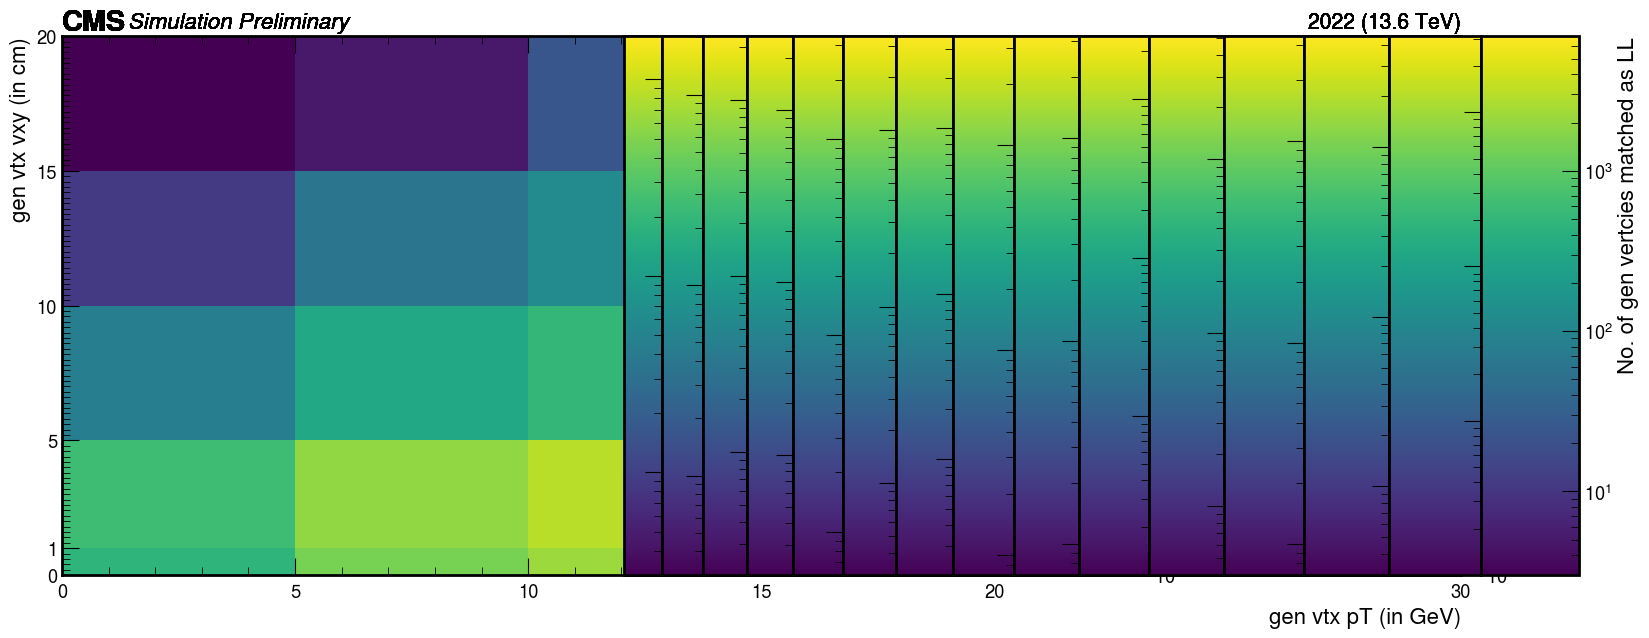

In [3]:
fig, ax = plt.subplots(figsize=(7,7))

#Numerator: No. of gen vertices matched as LL

# Plot settings
plot_dict = {
    'variable':'genvtx_pt_vxy',
    'cut': 'cut1',
    'year': 2022
}

style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "gen vtx pT (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': "gen vtx vxy (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': "No. of gen vertcies matched as LL",   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}

#signal points
samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }
}


h_list_lpt=[]
h_sum_lpt = None

sum_counts = None
sum_edges_pt = None
sum_edges_vxy = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
            counts_i = np.asarray(h_lpt[0], dtype=float) 
            edges_pt = np.asarray(h_lpt[1], dtype=float)
            edges_vxy = np.asarray(h_lpt[2], dtype=float)
            h_list_lpt.append((counts_i, edges_pt, edges_vxy))
            if sum_counts is None: 
                sum_counts = counts_i.copy() 
                sum_edges_pt = edges_pt.copy() 
                sum_edges_vxy = edges_vxy.copy()
            else: 
                sum_counts += counts_i
            
print ("sum_counts=", sum_counts)
print ("sum_edges_pt=", sum_edges_pt)
print ("sum_edges_vxy=", sum_edges_vxy)


sum_counts_den= [[ 503929. 1162701.  717099.  398744.  245197.]
 [ 700169. 1602467.  992198.  551334.  341502.]
 [ 401973. 1038971.  724622.  436283.  282855.]
 [ 214321.  607394.  464430.  297458.  201264.]
 [ 169640.  535063.  446211.  299735.  207255.]]
sum_edges_pt_den= [ 0.  5. 10. 15. 20. 30.]
sum_edges_vxy_den= [ 0.  1.  5. 10. 15. 20.]


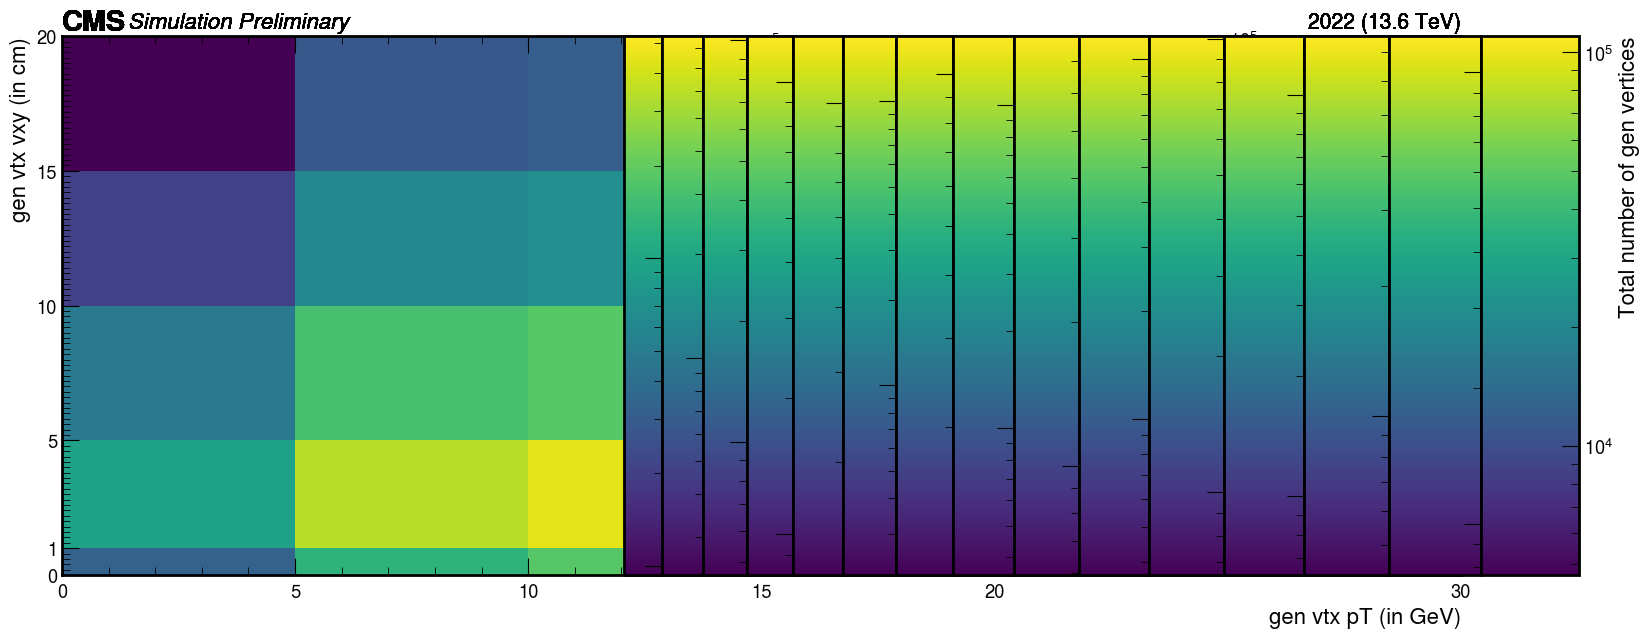

In [4]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'genvtx_pt_vxy_den',
    'cut': 'cut1',
    'year': 2022
}

style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "gen vtx pT (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': "gen vtx vxy (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': "Total number of gen vertices",   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}

#signal points
samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }
}


h_list_lpt_den=[]
h_sum_lpt_den = None

sum_counts_den = None
sum_edges_pt_den = None
sum_edges_vxy_den = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt_den = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
            counts_i_den = np.asarray(h_lpt_den[0], dtype=float) 
            edges_pt_den = np.asarray(h_lpt_den[1], dtype=float)
            edges_vxy_den = np.asarray(h_lpt_den[2], dtype=float)
            h_list_lpt_den.append((counts_i_den, edges_pt_den, edges_vxy_den))
            if sum_counts_den is None: 
                sum_counts_den = counts_i_den.copy() 
                sum_edges_pt_den = edges_pt_den.copy() 
                sum_edges_vxy_den = edges_vxy_den.copy()
            else: 
                sum_counts_den += counts_i_den
            
print ("sum_counts_den=", sum_counts_den)
print ("sum_edges_pt_den=", sum_edges_pt_den)
print ("sum_edges_vxy_den=", sum_edges_vxy_den)


In [5]:
def eff_determine_unc(n, d):
    eff = np.divide(n, d)
    unc = hist.intervals.ratio_uncertainty(n, d, 'efficiency')
    return eff, unc


efficiency_lpt, unc_lpt = eff_determine_unc(sum_counts, sum_counts_den)
print ("efficiency_lpt=", efficiency_lpt)
print ("unc_lpt=", unc_lpt)

efficiency_lpt= [[2.19951620e-02 6.60444947e-03 1.11560607e-03 2.68342596e-04
  8.15670665e-05]
 [4.30196138e-02 2.07311601e-02 7.13567252e-03 2.92925885e-03
  1.28549760e-03]
 [5.45459521e-02 3.81463968e-02 2.25096671e-02 1.20334737e-02
  7.30409574e-03]
 [7.53355947e-02 5.79294494e-02 4.34877161e-02 2.69752368e-02
  1.79018602e-02]
 [9.72235322e-02 7.78618593e-02 6.97203789e-02 4.80858091e-02
  3.59653567e-02]]
unc_lpt= [[[2.06649419e-04 7.51222549e-05 3.94139258e-05 2.58982307e-05
   1.80848011e-05]
  [2.42544068e-04 1.12568227e-04 8.45064288e-05 7.27814847e-05
   6.12943497e-05]
  [3.58313947e-04 1.87958663e-04 1.74284070e-04 1.65097594e-04
   1.60119276e-04]
  [5.70455879e-04 2.99841628e-04 2.99364477e-04 2.97135523e-04
   2.95633050e-04]
  [7.19866553e-04 3.66461441e-04 3.81409624e-04 3.90940950e-04
   4.09175366e-04]]

 [[2.08555641e-04 7.59758204e-05 4.08299542e-05 2.85261809e-05
   2.26194867e-05]
  [2.43853255e-04 1.13168049e-04 8.55058346e-05 7.46071219e-05
   6.42848852e-05

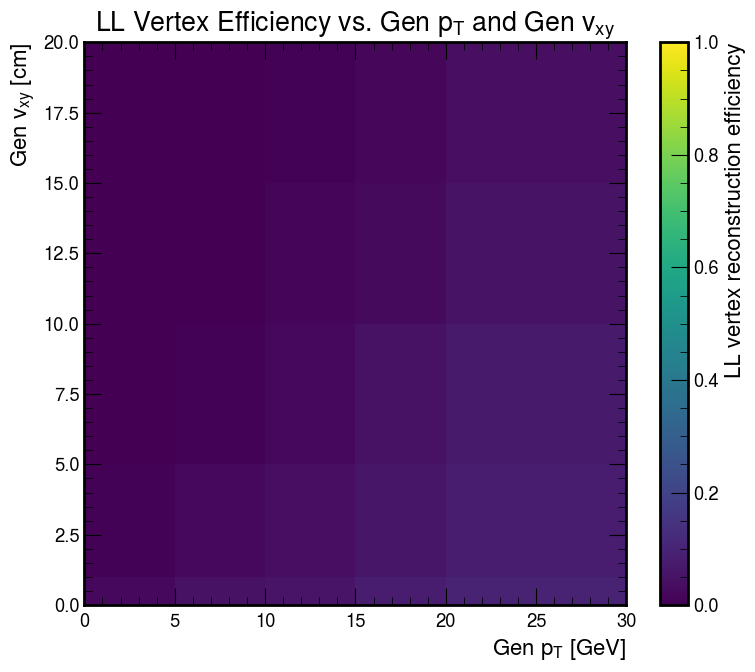

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))

mesh = ax.pcolormesh(
    sum_edges_pt,              # x-axis bin edges
    sum_edges_vxy,             # y-axis bin edges
    efficiency_lpt.T,          # transpose: (pT, vxy) -> (vxy, pT)
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LL vertex reconstruction efficiency")

ax.set_xlabel(r"Gen $p_{\mathrm{T}}$ [GeV]")
ax.set_ylabel(r"Gen $v_{xy}$ [cm]")
# ax.set_title(r"LL Vertex Efficiency vs. Gen $p_{\mathrm{T}}$ and Gen $v_{xy}$")

plt.tight_layout()
plt.show()

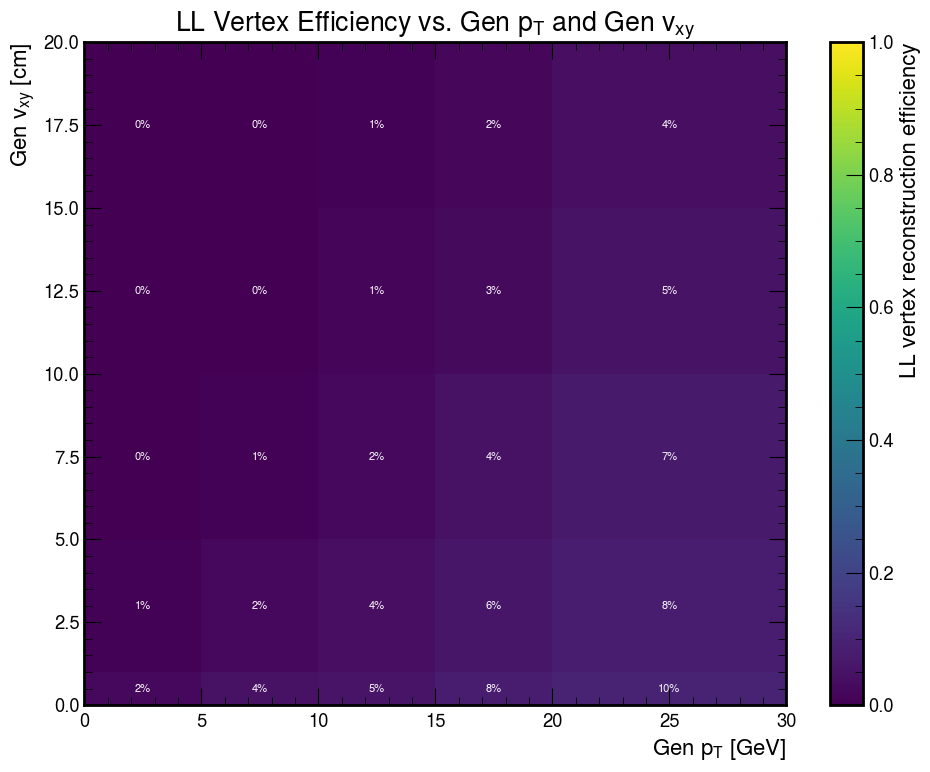

In [12]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts,
    sum_counts_den,
    out=np.full_like(sum_counts, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

# Make the 2D efficiency plot
fig, ax = plt.subplots(figsize=(10, 8))

efficiency_to_plot = efficiency_lpt.T

mesh = ax.pcolormesh(
    sum_edges_pt,
    sum_edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LL vertex reconstruction efficiency")

# Find the center of every bin
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Print the efficiency inside each bin
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Do not print anything in bins with no denominator events
        if np.isnan(efficiency):
            continue

        # Use white text on dark boxes and black text on bright boxes
        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            f"{100 * efficiency:.0f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=8
        )

ax.set_xlabel(r"Gen $p_{\mathrm{T}}$ [GeV]")
ax.set_ylabel(r"Gen $v_{xy}$ [cm]")
ax.set_title(
    r"LL Vertex Efficiency vs. Gen $p_{\mathrm{T}}$ and Gen $v_{xy}$"
)

plt.tight_layout()
plt.show()

ValueError: The number of FixedLocator locations (5), usually from a call to set_ticks, does not match the number of labels (4).

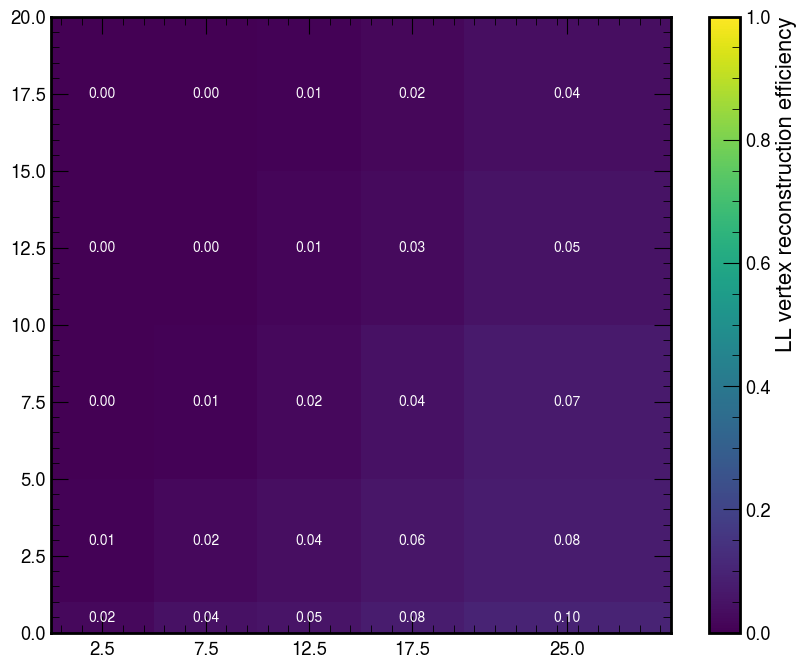

In [13]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts,
    sum_counts_den,
    out=np.full_like(sum_counts, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

# Matplotlib expects the array in the order [y-bin, x-bin]
efficiency_to_plot = efficiency_lpt.T

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the 2D efficiency
mesh = ax.pcolormesh(
    sum_edges_pt,               # x-axis: Gen pT bin edges
    sum_edges_vxy,              # y-axis: Gen vxy bin edges
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

# Add color bar
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LL vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Skip bins that have no denominator events
        if np.isnan(efficiency):
            continue

        # Choose text color based on the box color
        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            f"{efficiency:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Custom x-axis bin labels
x_labels = [
    r"Gen $p_{\mathrm{T}(ee)} < 5$ GeV",
    r"$5 < p_{\mathrm{T}(ee)} < 10$ GeV",
    r"$10 < p_{\mathrm{T}(ee)} < 20$ GeV",
    r"$p_{\mathrm{T}(ee)} > 20$ GeV"
]

# Custom y-axis bin labels
y_labels = [
    r"$L_{xy} < 1$ cm",
    r"$1 < L_{xy} < 5$ cm",
    r"$5 < L_{xy} < 10$ cm",
    r"$10 < L_{xy} < 15$ cm",
    r"Gen $L_{xy}(ee) > 15$ cm"
]

# Place the custom labels at the bin centers
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

# The bin labels contain all the axis information
ax.set_xlabel("")
ax.set_ylabel("")

ax.set_title(
    r"LL Vertex Efficiency vs. Gen $p_{\mathrm{T}}$ and Gen $v_{xy}$"
)

plt.tight_layout()
plt.show()

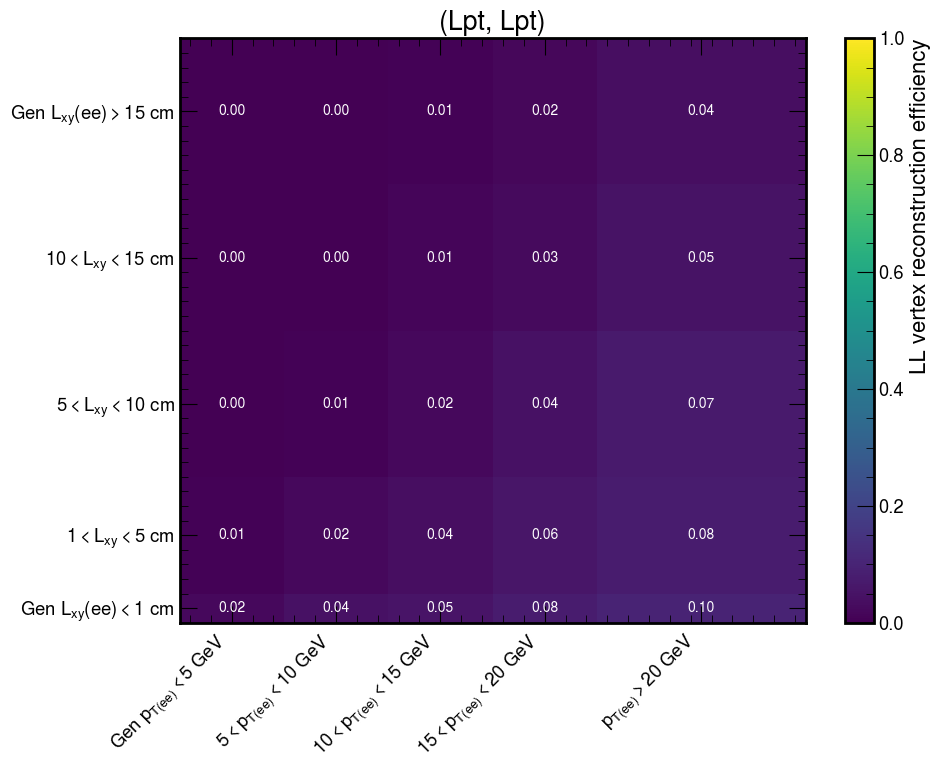

In [14]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts,
    sum_counts_den,
    out=np.full_like(sum_counts, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

efficiency_to_plot = efficiency_lpt.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    sum_edges_pt,
    sum_edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LL vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            f"{efficiency:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = sum_edges_pt[index]
    high_edge = sum_edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = sum_edges_vxy[index]
    high_edge = sum_edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("(Lpt, Lpt)")

plt.tight_layout()
plt.show()